
# 1. Problem Definition

## 1.1 Project Objective

Develop a machine learning classification model to predict whether recorded road crashes in Victoria result in severe or non-severe injury outcomes using historical crash data (2012–2025).

The project aims to evaluate prediction performance and identify factors associated with crash severity.

## 1.2 Target Variable

The `SEVERITY` column will be converted into a binary target:

- **1 — Severe:** Fatal or serious injury crashes (Severity 1 and 2).
- **0 — Non-Severe:** Other injury crashes (Severity 3).

Records with Severity 4 will be excluded.



# 2. Data Preparation

## 2.1 Mount Google Drive and Load Dataset

Load the cleaned master crash dataset from Google Drive for machine learning analysis, reusing the data prepared during the earlier project phases.


In [ ]:
from google.colab import drive
import pandas as pd

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Victoria RoadSafe - Crash Intelligence and Severity Prediction/master_crash_data.csv')
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (202297, 34)


,ACCIDENT_NO,ACCIDENT_DATE,ACCIDENT_TIME,ACCIDENT_TYPE_DESC,DCA_DESC,LIGHT_CONDITION,NO_OF_VEHICLES,NO_PERSONS_KILLED,NO_PERSONS_INJ_2,NO_PERSONS_INJ_3,...,LATITUDE,LONGITUDE,VEHICLE_COUNT,AVG_VEHICLE_AGE,TOTAL_OCCUPANTS,TOTAL_PEOPLE,SPEED_ZONE_CLEAN,LIGHT_CONDITION_DESC,WEATHER_GROUP,VEHICLE_GROUP
0,T20120002354,2012-01-31,10:35:00,Collision with vehicle,RIGHT THROUGH,1,2,0,1,1,...,-37.829544,144.96378,2.0,4.5,3.0,3,60.0,Day,Clear,Multiple vehicles
1,T20120002508,2012-02-02,07:55:00,Collision with vehicle,RIGHT THROUGH,1,2,0,2,1,...,-37.852745,145.15192,2.0,4.5,3.0,3,70.0,Day,Clear,Multiple vehicles
2,T20120003232,2012-02-10,14:20:00,Collision with vehicle,RIGHT THROUGH,1,2,0,1,0,...,-37.961050,145.14114,2.0,16.5,3.0,3,60.0,Day,Clear,Multiple vehicles
3,T20120004288,2012-02-17,08:40:00,Collision with vehicle,ENTERING PARKING,1,2,0,0,1,...,-37.778908,144.96013,2.0,1.0,2.0,2,40.0,Day,Clear,Multiple vehicles
4,T20120004516,2012-02-24,15:30:00,Struck Pedestrian,PED EMERGES FROM IN FRONT OF PARKED OR STATION...,1,1,0,0,1,...,-37.792400,144.94131,1.0,15.0,1.0,2,50.0,Day,Clear,Single vehicle


## 2.2 Filter the Study Period

Retain crash records from 2012–2025, excluding incomplete 2026 data to ensure a consistent historical analysis period.


In [ ]:
df = df[df['YEAR'].between(2012, 2025)].copy()

print("Dataset shape:", df.shape)


Dataset shape: (202069, 34)



## 2.3 Create the Binary Target Variable

The original `SEVERITY` column classifies crashes into four categories. For binary classification, we will create a new target variable called `SEVERE_CRASH`:

- **1 — Severe Crash:** Fatal (Severity 1) or serious injury (Severity 2).
- **0 — Non-Severe Crash:** Other injury (Severity 3).

Records with Severity 4 will be excluded because they do not belong to the defined injury categories.

This transformation allows the machine learning model to learn patterns associated with severe and non-severe crash outcomes. The original `SEVERITY` column will not be used as a predictor, as it directly reveals the target.


In [ ]:

df = df[df['SEVERITY'].isin([1, 2, 3])].copy()

df['SEVERE_CRASH'] = df['SEVERITY'].isin([1, 2]).astype(int)

print(df['SEVERE_CRASH'].value_counts())


SEVERE_CRASH
0    126421
1     75644
Name: count, dtype: int64



## 2.4 Class Distribution & Balance

Examine the distribution of severe and non-severe crashes to identify potential class imbalance before model training.

Class imbalance can affect model performance when one category has significantly more observations than another.


In [ ]:

class_counts = df['SEVERE_CRASH'].value_counts().sort_index()
class_percent = df['SEVERE_CRASH'].value_counts(normalize=True).sort_index() * 100

print("Class Counts:")
print(class_counts)

print("\nClass Percentages:")
print(class_percent.round(2))


Class Counts:
SEVERE_CRASH
0    126421
1     75644
Name: count, dtype: int64

Class Percentages:
SEVERE_CRASH
0    62.56
1    37.44
Name: proportion, dtype: float64



**Observation:** The dataset is moderately imbalanced, with 62.56% non-severe and 37.44% severe crashes. Both classes have sufficient observations for initial model training. We will evaluate performance using precision, recall, F1-score, and ROC-AUC rather than accuracy alone.



## 2.5 Feature Selection

The model will use temporal, geographic, road infrastructure, and environmental characteristics to estimate the likelihood of a severe outcome if a crash occurs.

### Selected Features

| Category | Features | Reason |
|---|---|---|
| Temporal | MONTH, DAY_OF_WEEK, HOUR | Capture seasonal, weekly, and hourly patterns. |
| Road Infrastructure | SPEED_ZONE_CLEAN, ROAD_TYPE, ROAD_GEOMETRY_DESC | Describe speed limits, road classifications, and intersection layouts. |
| Environmental | LIGHT_CONDITION_DESC, WEATHER_GROUP, SURFACE_COND_DESC | Capture lighting, weather, and road surface conditions. |
| Geographic | LGA_NAME, DEG_URBAN_NAME | Represent local and urban-rural differences. |

### Excluded Features

- **Data Leakage:** SEVERITY, NO_PERSONS_KILLED, NO_PERSONS_INJ_2, and NO_PERSONS_INJ_3 directly reveal crash outcomes.
- **Post-Crash Information:** ACCIDENT_TYPE_DESC, DCA_DESC, NO_OF_VEHICLES, VEHICLE_COUNT, VEHICLE_GROUP, AVG_VEHICLE_AGE, TOTAL_OCCUPANTS, and TOTAL_PEOPLE describe the incident or vehicles involved.
- **Redundant Information:** ACCIDENT_TIME, SPEED_ZONE, LIGHT_CONDITION, and ATMOSPH_COND_DESC have alternative features already selected.
- **Identifiers and High-Detail Locations:** ACCIDENT_NO, ROAD_NAME, LATITUDE, and LONGITUDE are excluded to reduce overfitting to individual locations.
- **Other Exclusions:** RMA is omitted due to missing values and overlap with road classifications. ACCIDENT_DATE and YEAR will be used for chronological data splitting rather than as predictors.

**Target Variable:** `SEVERE_CRASH` (1 = Severe, 0 = Non-Severe).

The model estimates severity conditional on a crash occurring under specified conditions. It does not predict whether a crash will occur.


In [ ]:

features = [
    'MONTH', 'DAY_OF_WEEK', 'HOUR',
    'SPEED_ZONE_CLEAN', 'ROAD_TYPE', 'ROAD_GEOMETRY_DESC',
    'LIGHT_CONDITION_DESC', 'WEATHER_GROUP', 'SURFACE_COND_DESC',
    'LGA_NAME', 'DEG_URBAN_NAME'
]

X = df[features].copy()
y = df['SEVERE_CRASH']

print("Feature dataset:", X.shape)
print("Target dataset:", y.shape)


Feature dataset: (202065, 11)
Target dataset: (202065,)



## 2.6 Missing Value Analysis

Examine the number and percentage of missing values in the selected features to determine appropriate preprocessing methods before model training.


In [ ]:

missing_summary = pd.DataFrame({
    'Missing Count': X.isnull().sum(),
    'Missing (%)': (X.isnull().mean() * 100).round(2)
})

print(missing_summary)


                      Missing Count  Missing (%)
MONTH                             0          0.0
DAY_OF_WEEK                       0          0.0
HOUR                              0          0.0
SPEED_ZONE_CLEAN              15156          7.5
ROAD_TYPE                         0          0.0
ROAD_GEOMETRY_DESC                0          0.0
LIGHT_CONDITION_DESC              0          0.0
WEATHER_GROUP                     0          0.0
SURFACE_COND_DESC                 0          0.0
LGA_NAME                          0          0.0
DEG_URBAN_NAME                    0          0.0



**Observation:** Only `SPEED_ZONE_CLEAN` contains missing values (15,156 records; 7.50%). All other selected features are complete. Missing speed-zone values will be handled during preprocessing without removing these crash records.



## 2.7 Missing Value Treatment Strategy

Treat `SPEED_ZONE_CLEAN` as a categorical feature and represent its missing values using an "Unknown" category.

This preserves all crash records without assuming an unreported speed limit. Missing-value handling will be implemented within the preprocessing pipeline after the train/test split.



# 3. Train/Test Split

## 3.1 Chronological Data Split

Split the dataset chronologically to evaluate model performance on newer crash records.

- **Training set (2012–2022):** Used to learn patterns associated with crash severity.
- **Testing set (2023–2025):** Used to evaluate performance on unseen, more recent records.

A time-based split provides a more realistic evaluation of future predictive performance and reduces the risk of temporal data leakage.


In [ ]:

train_mask = df['YEAR'] <= 2022
test_mask = df['YEAR'] >= 2023

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (155638, 11)
Testing features: (46427, 11)
Training target: (155638,)
Testing target: (46427,)



# 4. Data Preprocessing

Data preprocessing prepares the selected features for machine learning by handling missing values and converting categorical variables into numerical representations.

## 4.1 Identify Feature Types

All 11 selected features will initially be treated as categorical.

Although `MONTH`, `HOUR`, and `SPEED_ZONE_CLEAN` contain numerical values, they represent distinct time periods or speed-limit categories. Treating them as categorical allows the model to learn individual patterns without assuming a linear relationship.

Categorical features will be converted into machine-readable form using One-Hot Encoding.


In [ ]:

categorical_features = [
    'MONTH', 'DAY_OF_WEEK', 'HOUR',
    'SPEED_ZONE_CLEAN', 'ROAD_TYPE', 'ROAD_GEOMETRY_DESC',
    'LIGHT_CONDITION_DESC', 'WEATHER_GROUP', 'SURFACE_COND_DESC',
    'LGA_NAME', 'DEG_URBAN_NAME'
]

print("Categorical features:", len(categorical_features))


Categorical features: 11



## 4.2 Create the Preprocessing Pipeline

Prepare the selected categorical features for machine learning by:

- **Missing Value Handling:** Represent unknown speed limits as a separate "Unknown" category to preserve all crash records.
- **One-Hot Encoding:** Convert categorical values into binary (0/1) columns without introducing an artificial numerical order.
- **Pipeline:** Combine preprocessing steps to ensure consistent transformations across training and testing datasets.

The preprocessing pipeline will be fitted using training data only to prevent data leakage.


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

X_train = X_train.copy()
X_test = X_test.copy()

X_train['SPEED_ZONE_CLEAN'] = X_train['SPEED_ZONE_CLEAN'].fillna('Unknown').astype(str)
X_test['SPEED_ZONE_CLEAN'] = X_test['SPEED_ZONE_CLEAN'].fillna('Unknown').astype(str)

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('categorical', categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")


Preprocessing pipeline created successfully.



## 4.3 Apply and Verify Preprocessing

Fit the preprocessing pipeline on the training dataset and apply the same transformations to the testing dataset.

Verify that both datasets retain their original number of records and contain the same number of encoded features.


In [ ]:

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)


Training shape: (155638, 275)
Testing shape: (46427, 275)



# 5. Model Development

Develop and evaluate machine learning models to classify reported road crashes as severe or non-severe using road, temporal, geographic, and environmental features.

## 5.1 Logistic Regression — Baseline Model

Train a Logistic Regression classifier as the initial benchmark.

The model learns relationships between the selected features and the binary severity target using historical training data (2012–2022).

Its performance will be evaluated separately on unseen crashes from 2023–2025.


In [ ]:

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.



## 5.2 Evaluate the Baseline Model

Evaluate Logistic Regression on the unseen 2023–2025 testing dataset.

The following metrics will be used:

- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Reliability of predicted severe-crash classifications.
- **Recall:** Ability to identify actual severe crashes.
- **F1-Score:** Balance between precision and recall.
- **ROC-AUC:** Ability to distinguish severe from non-severe crashes across classification thresholds.

Recall is particularly important because failing to identify a severe crash is a significant concern in road safety analysis.


In [ ]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

y_pred = lr_model.predict(X_test_processed)
y_prob = lr_model.predict_proba(X_test_processed)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-Score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))


Accuracy: 0.655
Precision: 0.502
Recall: 0.218
F1-Score: 0.304
ROC-AUC: 0.621



### Observation

The baseline Logistic Regression model achieved 65.5% accuracy and a ROC-AUC of 0.621 on the 2023–2025 test dataset.

However, severe-crash recall was only 21.8%, indicating that approximately 78% of actual severe crashes were incorrectly classified as non-severe.

The low F1-score (0.304) further highlights weak performance in identifying severe crashes. Therefore, overall accuracy alone is insufficient for evaluating this road-safety classification model.

The baseline model requires improvement, particularly in severe-crash recall, while monitoring precision and false-positive predictions.



## 5.3 Confusion Matrix

A confusion matrix evaluates classification performance by comparing actual and predicted crash severity.

It identifies four outcomes:

- **True Negative (TN):** Non-severe crashes correctly classified.
- **False Positive (FP):** Non-severe crashes incorrectly classified as severe.
- **False Negative (FN):** Severe crashes incorrectly classified as non-severe.
- **True Positive (TP):** Severe crashes correctly classified.

False negatives are particularly important because they represent severe crashes missed by the model.


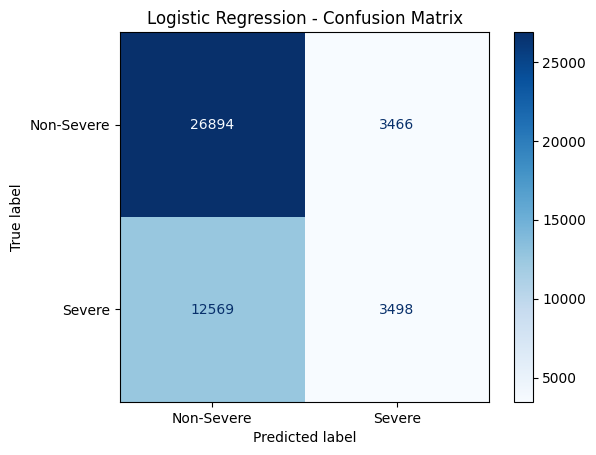

In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Non-Severe', 'Severe']
).plot(cmap='Blues')

plt.title('Logistic Regression - Confusion Matrix')
plt.show()



### Observation

The confusion matrix shows that Logistic Regression correctly classified 26,894 non-severe crashes and 3,498 severe crashes.

However, it incorrectly classified 12,569 severe crashes as non-severe, resulting in a high false-negative rate of 78.2%.

The model performs considerably better at identifying non-severe crashes than severe crashes. Improving severe-crash recall should therefore be a priority, while monitoring the increase in false positives.



## 5.4 Improve Logistic Regression Using Class Weights

The baseline Logistic Regression model achieved only 21.8% recall for severe crashes, indicating a high number of false negatives.

To address class imbalance, compare:

- **Baseline Logistic Regression:** Default class weights.
- **Balanced Logistic Regression:** Automatically adjusts class weights according to class frequency.

Use 2012–2020 for training and 2021–2022 for validation. This preserves chronological order and avoids using the final 2023–2025 test dataset to select model improvements.

Compare precision, recall, F1-score, and ROC-AUC to assess whether class weighting improves severe-crash identification.


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Chronological training and validation split
train_idx = df.loc[X_train.index, 'YEAR'] <= 2020

X_dev = X_train.loc[train_idx]
X_val = X_train.loc[~train_idx]

y_dev = y_train.loc[train_idx]
y_val = y_train.loc[~train_idx]

results = []

for name, weight in [('Baseline', None), ('Balanced', 'balanced')]:
    model = Pipeline([
        ('preprocessing', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, class_weight=weight))
    ])

    model.fit(X_dev, y_dev)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        'Model': name,
        'Precision': round(precision_score(y_val, predictions), 3),
        'Recall': round(recall_score(y_val, predictions), 3),
        'F1-Score': round(f1_score(y_val, predictions), 3),
        'ROC-AUC': round(roc_auc_score(y_val, probabilities), 3)
    })

pd.DataFrame(results)


,Model,Precision,Recall,F1-Score,ROC-AUC
0,Baseline,0.521,0.230,0.320,0.629
1,Balanced,0.434,0.607,0.506,0.629



### Observation

The balanced Logistic Regression model improved severe-crash recall from 23.0% to 60.7% and F1-score from 0.320 to 0.506 on the 2021–2022 validation dataset.

However, precision decreased from 52.1% to 43.4%, indicating more false-positive predictions.

ROC-AUC remained unchanged at 0.629, suggesting that class weighting improved classification at the default threshold without improving overall class discrimination.

The balanced model is preferable for the current recall-focused objective, although its precision and discrimination remain limited.



## 5.5 Random Forest Classification

Train a Random Forest classifier to capture potentially complex relationships between road, time, location, and environmental features.

Use the same chronological training (2012–2020) and validation (2021–2022) datasets as Logistic Regression for a fair comparison.

Apply balanced class weights to account for class imbalance, and evaluate the model's ability to identify severe crashes.


In [ ]:

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_dev, y_dev)

print("Random Forest model trained successfully.")


Random Forest model trained successfully.



## 5.6 Evaluate Random Forest Model

Evaluate the Random Forest classifier on the 2021–2022 validation dataset.

Calculate precision, recall, F1-score, and ROC-AUC to assess its ability to identify severe crashes.

Compare its performance with the baseline and balanced Logistic Regression models using the same validation period.


In [ ]:

rf_pred = rf_model.predict(X_val)
rf_prob = rf_model.predict_proba(X_val)[:, 1]

rf_results = {
    'Model': 'Random Forest',
    'Precision': round(precision_score(y_val, rf_pred), 3),
    'Recall': round(recall_score(y_val, rf_pred), 3),
    'F1-Score': round(f1_score(y_val, rf_pred), 3),
    'ROC-AUC': round(roc_auc_score(y_val, rf_prob), 3)
}

comparison = pd.DataFrame(results + [rf_results])

comparison


,Model,Precision,Recall,F1-Score,ROC-AUC
0,Baseline,0.521,0.230,0.320,0.629
1,Balanced,0.434,0.607,0.506,0.629
2,Random Forest,0.451,0.294,0.356,0.594



## 5.7 Model Comparison and Selection

Three classification models were evaluated on the same chronological validation dataset (2021–2022).

### Observation

Balanced Logistic Regression achieved the highest severe-crash recall (60.7%) and F1-score (0.506), outperforming baseline Logistic Regression and Random Forest.

Random Forest achieved lower recall (29.4%) and ROC-AUC (0.594), indicating no improvement over Logistic Regression with the tested configuration.

### Model Selection

Balanced Logistic Regression is selected as the leading candidate because identifying severe crashes is the primary classification objective.

However, its precision (43.4%) and ROC-AUC (0.629) indicate limited predictive reliability. Further validation and final testing are required before drawing conclusions about its practical suitability.



## 5.8 Final Model Training and Testing

Retrain the selected Balanced Logistic Regression model using historical crash records from 2012–2022.

Evaluate its performance on the held-out 2023–2025 test dataset to assess how well it generalises to later crashes.

The final model uses the same preprocessing pipeline and class-weight settings selected during validation. No additional model selection or tuning will be performed using the test dataset.


In [ ]:

final_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ))
])

final_model.fit(X_train, y_train)

final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, final_pred), 3))
print("Precision:", round(precision_score(y_test, final_pred), 3))
print("Recall:", round(recall_score(y_test, final_pred), 3))
print("F1-Score:", round(f1_score(y_test, final_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, final_prob), 3))


Accuracy: 0.579
Precision: 0.424
Recall: 0.603
F1-Score: 0.498
ROC-AUC: 0.619



### Final Model Observation

The final Balanced Logistic Regression model achieved 57.9% accuracy, 42.4% precision, 60.3% recall, an F1-score of 0.498, and ROC-AUC of 0.619 on the held-out 2023–2025 test dataset.

Compared with the original Logistic Regression baseline, severe-crash recall improved substantially from 21.8% to 60.3%, while F1-score increased from 0.304 to 0.498.

However, precision and accuracy decreased, reflecting an increase in false-positive classifications. ROC-AUC remained approximately 0.62, indicating limited overall discrimination between severe and non-severe crashes.

The final model demonstrates improved identification of severe crashes but is not sufficiently reliable for operational road-safety decisions without further validation and improvement.



# 6. Model Conclusions and Limitations

## 6.1 Key Findings

This project developed machine learning models to classify reported Victorian road crashes as severe (fatal or serious injury) or non-severe (other injury) using historical data from 2012–2025.

Three models were compared using chronological validation: Baseline Logistic Regression, Balanced Logistic Regression, and Random Forest.

**Balanced Logistic Regression was selected** because it achieved the highest recall and F1-score on the validation dataset.

### Final Test Performance (2023–2025)

| Metric | Final Result |
|---|---:|
| Accuracy | 57.9% |
| Precision | 42.4% |
| Recall | 60.3% |
| F1-Score | 0.498 |
| ROC-AUC | 0.619 |

### Key Observations

- Severe-crash recall improved from 21.8% in the baseline model to 60.3% in the balanced model.
- The final model identified approximately 60% of actual severe crashes, but missed approximately 40%.
- Lower precision indicates that many non-severe crashes were incorrectly classified as severe.
- ROC-AUC of 0.619 indicates limited ability to distinguish between severity classes.

## 6.2 Limitations

- The dataset contains reported crashes only. The model predicts severity conditional on a crash occurring, not the probability of a crash occurring.
- Only road, temporal, geographic, and environmental features were selected to support a proactive prediction scenario.
- Important influences such as driver behaviour, vehicle speed at impact, and safety equipment were not included.
- The model's limited discrimination and false-positive rate restrict its suitability for operational decisions.
- Observed relationships should not be interpreted as evidence of causation.

## 6.3 Final Conclusion

The project demonstrates an end-to-end machine learning workflow involving feature selection, chronological data splitting, preprocessing, model comparison, and evaluation on unseen historical data.

Balanced Logistic Regression improved severe-crash detection compared with the baseline. However, predictive performance remains modest.

The resulting model should be considered a proof of concept for historical crash-severity classification rather than a validated real-world road-safety decision system.
